# Finetuneando Stable Diffusion con LoRA

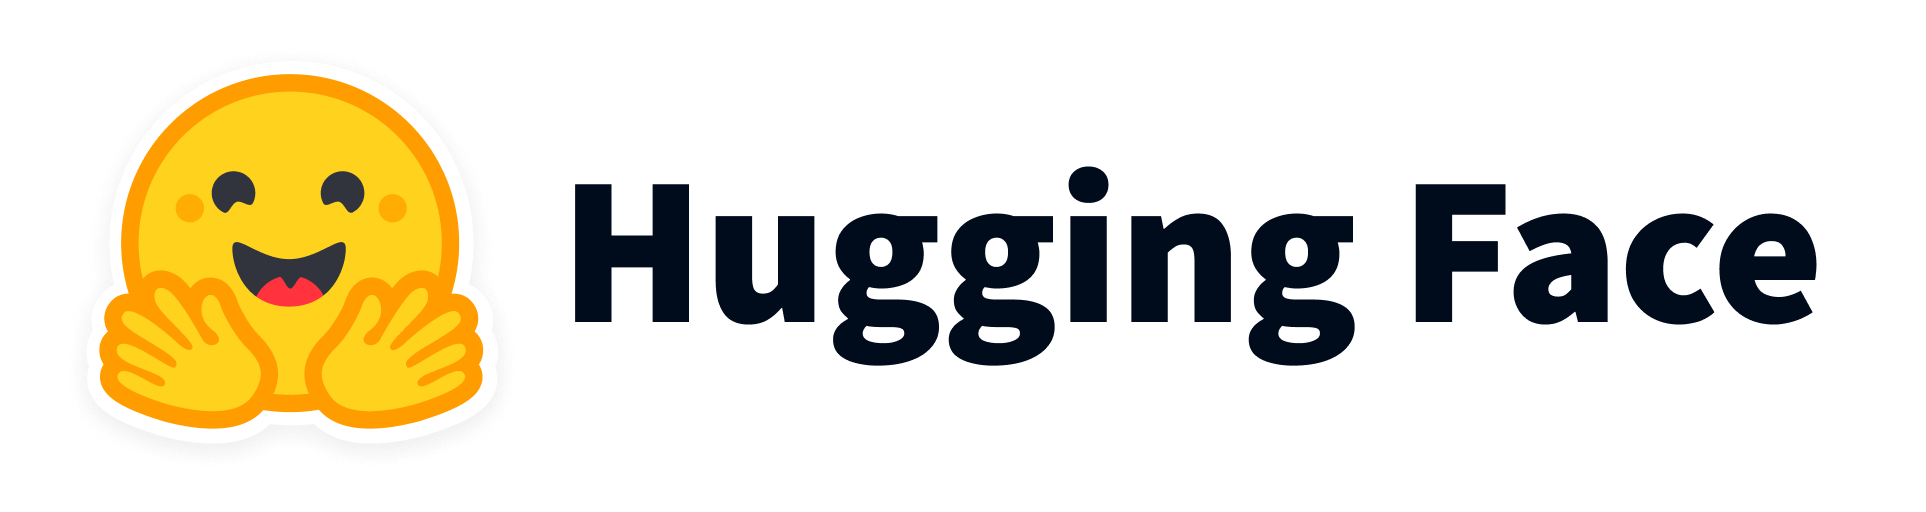

version 2.0 (LoRA)

# 0. Instalación de librerías

In [1]:
!pip install -qq diffusers datasets accelerate peft

# Colab trae preinstalada una version antigua de torchao que es incompatible con peft.
# peft solo la usa para cuantizacion (no la necesitamos), asi que la desinstalamos:
!pip uninstall -qq -y torchao

In [2]:
# Importamos las librerias necesarias:
from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL, LMSDiscreteScheduler
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import os
from tqdm import tqdm

In [3]:
# Vamos a utilizar GPU, necesaria para el entrenamiento:

device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


# 1. Comportamiento original del modelo pre-entrenado

In [4]:
pretrained_model_name = "CompVis/stable-diffusion-v1-4"

# Cargamos un modelo pre-entrenado Stable Diffusion:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
).to(device)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

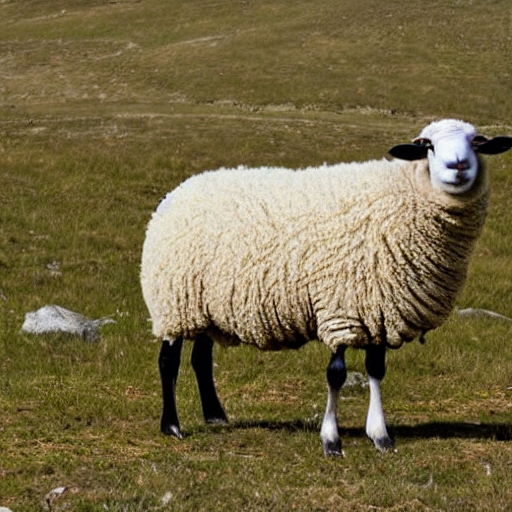

In [5]:
# Vamos a generar una imagen con un prompt:
prompt = "an image of a sheep"

# Semilla de reproducibilidad: mismo prompt + misma semilla = misma imagen
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

image = pipe(prompt, generator=generator).images[0]

image

# 2. Cargamos el dataset para finetunear

In [6]:
# Cargando el dataset de Pokemon con texto:
dataset_name = "reach-vb/pokemon-blip-captions"

dataset = load_dataset(dataset_name, split="train")

# Comprobamos el tamaño del dataset y de sus imagenes:
dataset_size = len(dataset)
size = dataset[0]["image"].size
print(f"Dataset con {dataset_size} imagenes, de tamaño {size} cada una")

Dataset con 833 imagenes, de tamaño (1280, 1280) cada una


In [7]:
# Definimos las transformaciones necesarias para el dataset:
# La resolucion del modelo la podemos encontrar en su model card:
resolution = 512
image_transforms = transforms.Compose([
    transforms.Resize((resolution, resolution)),             # resizing
    transforms.ToTensor(),                                   # convertir a tensor
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # normalizacion
])

Imagen transformada:


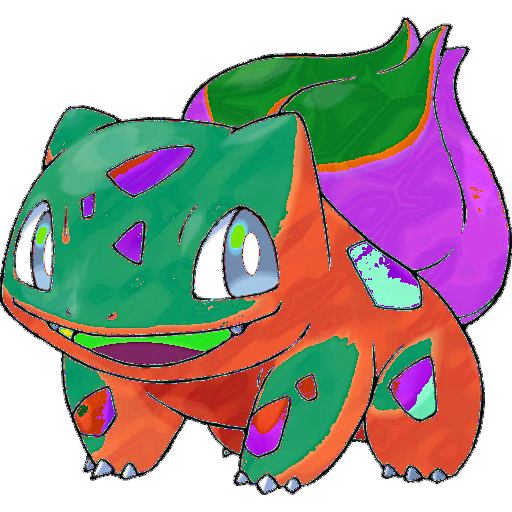

In [9]:
# Aplicamos la transformacion a una imagen del dataset:
original_image = dataset[0]["image"]
transformed_image = image_transforms(original_image)
transformed_pil_image = transforms.ToPILImage()(transformed_image)

print("Imagen transformada:")
transformed_pil_image

In [10]:
# Creamos un Dataset wrapper para la hora del entrenamiento:
batch_size = 3  # no puede ser mayor por la limitacion de GPU

class Text2ImageDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        example = self.dataset[idx]
        image = image_transforms(example["image"].convert("RGB"))
        token = tokenizer(example["text"], padding="max_length", truncation=True, max_length=tokenizer.model_max_length, return_tensors="pt")
        return {
            "pixel_values": image,
            "input_ids": token.input_ids.squeeze(0),
            "attention_mask": token.attention_mask.squeeze(0),
        }

train_dataset = Text2ImageDataset(dataset)
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# 3. Cargamos las componentes del modelo por separado

In [11]:
# Antes de cargar todas las componentes en GPU, la vaciamos:
del pipe
torch.cuda.empty_cache()

In [12]:
# Tokenizador:
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder='tokenizer')

# Scheduler:
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")

# Text Encoder (CLIP):
text_encoder = CLIPTextModel.from_pretrained(
    pretrained_model_name,
    subfolder="text_encoder",
).to(device)

# VAE: Autoencoder:
vae = AutoencoderKL.from_pretrained(
    pretrained_model_name,
    subfolder="vae",
).to(device)

# La UNet:
unet = UNet2DConditionModel.from_pretrained(
    pretrained_model_name,
    subfolder="unet",
).to(device)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

In [13]:
# Congelamos los pesos del VAE y del Text Encoder, no se entrenan.
# La UNet original tambien quedara congelada: al añadir la LoRA (siguiente seccion), peft pone
# requires_grad=False en los pesos originales y solo deja entrenables las matrices de la LoRA.
vae.eval()
text_encoder.eval()

for param in vae.parameters():
    param.requires_grad = False
for param in text_encoder.parameters():
    param.requires_grad = False

# 4. Añadimos la LoRA y preparamos el entrenamiento

En vez de finetunear los ~860M de parámetros de la UNet, usamos LoRA (Low-Rank Adaptation):

- Los pesos originales de la UNet se congelan.
- En las capas de atención (`to_q`, `to_k`, `to_v` y `to_out.0`) se añaden dos matrices pequeñas de bajo rango (`r`) cuyo producto se suma al peso original. Solo se entrenan esas matrices.
- Resultado: entrenamos <1% de los parámetros, necesitamos mucha menos memoria y el fichero final pesa unos MB en lugar de ~3.4 GB.
- La LoRA se carga encima del modelo base, así que se puede activar, desactivar o graduar su intensidad.

In [14]:
# Hiperparametros de la LoRA:
lora_rank = 6     # rango de las matrices de bajo rango (4-16 suele ser suficiente)
lora_alpha = 6    # factor de escala de la LoRA (suele igualarse al rango)

# Inyectamos la LoRA en las capas de atencion de la UNet. peft congela los pesos base y crea
# las matrices de bajo rango entrenables:
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name="pokemon")

# Comprobamos cuantos parametros entrenamos realmente (solo la LoRA):
lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parametros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

# Optimizador SOLO sobre los parametros de la LoRA:
learning_rate = 1e-4
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

# Acelerador:
accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print(accelerator.device)

Parametros entrenables (LoRA): 1,195,776 de 860,716,740 (0.14%)
cuda


# 5. Proceso de entrenamiento: finetuning con LoRA

El bucle es idéntico al del finetuning completo (VAE-encode → añadir ruido → predecir ruido → MSE). La única diferencia es que el optimizador solo actualiza los pesos de la LoRA.

In [15]:
# Training loop:
num_epochs = 5

unet.train()
for epoch in range(num_epochs):
    progress_bar = tqdm(train_dataloader, desc=f"Epoch {epoch}")

    for batch in progress_bar:

        # Se pasan los pixeles al espacio latente con el encoder del VAE:
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215

        # Proceso de difusion hacia delante:
        # 1. Creamos ruido aleatorio
        noise = torch.randn_like(latents)
        # 2. Cogemos un timestep aleatorio:
        timesteps = torch.randint(0, noise_scheduler.config.num_train_timesteps, (latents.shape[0],), device=latents.device).long()
        # 3. Añadimos ruido al vector del espacio latente:
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # Codificamos el texto:
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # Con el vector con ruido, el timestep, y el vector de texto, hacemos la prediccion de ruido:
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # Calculamos el error y actualizamos los parametros (solo los de la LoRA):
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        progress_bar.set_postfix(loss=loss.item())

Epoch 4: 100%|██████████| 278/278 [14:56<00:00,  3.22s/it, loss=0.0278]


# 6. Generamos imágenes con la LoRA entrenada:

La UNet que acabamos de entrenar ya lleva la LoRA inyectada, así que la usamos directamente en el pipeline junto con el VAE, el text encoder y el tokenizer que ya teníamos cargados.

In [16]:
# Recuperamos la UNet entrenada (con la LoRA dentro) y la ponemos en modo evaluacion:
unet = accelerator.unwrap_model(unet)
unet.eval()

# Montamos el pipeline reutilizando las componentes que ya tenemos en GPU:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
).to(device)

print('Pipeline con LoRA listo!')

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Pipeline con LoRA listo!


In [17]:
# (Opcional) Podemos graduar la intensidad de la LoRA entre 0 (modelo base) y 1 (LoRA completa):
pipe.set_adapters(["pokemon"], adapter_weights=[1.0])

  0%|          | 0/50 [00:00<?, ?it/s]

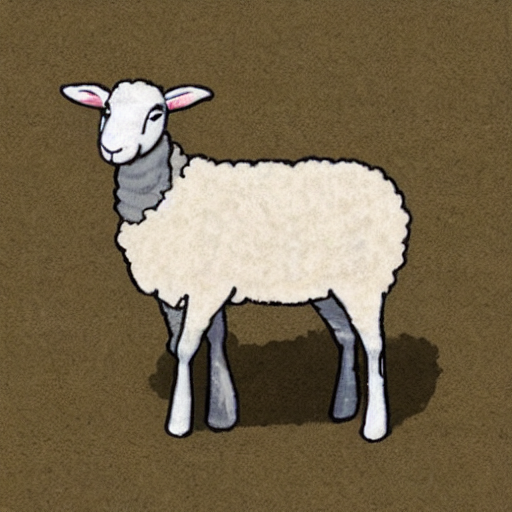

In [18]:
# Generamos Pokemons con el modelo base + LoRA:
prompt = "an image of a sheep"

# Misma semilla que antes para comparar base vs LoRA con el mismo ruido inicial
seed = 42
generator = torch.Generator(device=device).manual_seed(seed)

image = pipe(prompt, generator=generator).images[0]

image